# European Renewable Electricity Analysis (2015–2025)

**Noah Nentwig** · Python, pandas, data validation, exploratory analysis and dashboard reporting.

This project examines recorded renewable electricity generation across the European countries represented in the supplied dataset. Generation growth alone does not establish a greener electricity mix.

**Execution status:** Executed from start to finish using the two original CSVs supplied by the author. The per-capita conversion is corrected before plotting and paths are relative to this repository. The presentation and dashboard PDF remain original exports and have not been regenerated.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

Matplotlib is building the font cache; this may take a moment.


## 1. Load the source data

The two original CSVs supplied by the author are included in `data/raw/`. Provider labels are supplied metadata; external provenance and licensing have not been independently verified.


In [2]:
from pathlib import Path

# Supports launching Jupyter from either the repository root or notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"
required_files = [DATA_DIR / "renewable_energy_readings.csv", DATA_DIR / "countries.csv"]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Add the original source CSVs before running: " + ", ".join(missing_files))

df_1 = pd.read_csv(required_files[0])
df_2 = pd.read_csv(required_files[1])
for frame in (df_1, df_2):
    print(frame.shape)
    print(frame.dtypes)
    display(frame.head())
    display(frame.describe())


(17947, 15)
record_id                               int64
country_id                              int64
period_date                               str
year                                    int64
month                                   int64
energy_source                             str
generation_gwh                        float64
installed_capacity_mw                 float64
national_consumption_gwh              float64
renewable_share_of_consumption_pct    float64
capacity_factor_pct                   float64
co2_avoided_kt                        float64
data_status                               str
data_provider                             str
last_updated                              str
dtype: object


,record_id,country_id,period_date,year,month,energy_source,generation_gwh,installed_capacity_mw,national_consumption_gwh,renewable_share_of_consumption_pct,capacity_factor_pct,co2_avoided_kt,data_status,data_provider,last_updated
0,78605890,2635,2021-02-01,2021,2,hydro,50.55,226.1,296.5,17.05,30.6,19.2,Prov.,ENTSO-E,2022-05-06
1,59824540,1464,2024-10-01,2024,10,wind,1838.44,9587.0,3102.1,59.26,26.3,698.6,Final,ENTSO-E,2025-08-17
2,65789770,8170,2023-03-01,2023,3,solar,38.35,306.0,423.5,9.06,17.2,14.6,FINAL,Eurostat,2024-05-04
3,73530108,6339,2021-09-01,2021,9,biomass,1221.30,12645.2,36161.0,3.38,13.2,464.1,est,Eurostat,2022-02-08
4,80787031,2250,2017-07-01,2017,7,solar,110.58,430.5,396.8,27.87,35.2,42.0,Final,ENTSO-E,2018-02-03


,record_id,country_id,year,month,generation_gwh,installed_capacity_mw,national_consumption_gwh,renewable_share_of_consumption_pct,capacity_factor_pct,co2_avoided_kt
count,1.794700e+04,17947.000000,17947.000000,17947.000000,1.760700e+04,17853.000000,17947.000000,17607.000000,17795.000000,17947.000000
mean,5.497017e+07,5334.432886,2020.129715,6.492561,4.792444e+03,4207.197944,8375.268507,9.393633,25.432931,289.321864
std,2.596238e+07,2405.484178,3.113264,3.453063,1.332551e+05,7598.235062,10626.583235,12.072794,10.861555,578.117361
min,1.001245e+07,1039.000000,2015.000000,1.000000,-7.812730e+03,5.800000,174.300000,0.050000,5.600000,0.500000
25%,3.253303e+07,3829.000000,2018.000000,3.000000,4.892500e+01,289.300000,1186.800000,2.555000,14.200000,19.100000
50%,5.491437e+07,4896.000000,2020.000000,6.000000,1.925000e+02,1355.100000,4264.100000,5.900000,29.000000,74.300000
75%,7.735458e+07,6431.000000,2023.000000,9.000000,7.692600e+02,4597.800000,10473.500000,11.980000,33.900000,290.000000
max,9.998301e+07,9826.000000,2025.000000,12.000000,1.249710e+07,75289.100000,51273.000000,132.200000,54.000000,7595.500000


(38, 9)
country_id                           int64
country_name                           str
iso2_code                              str
region                                 str
eu_member                             bool
population_millions                float64
gdp_per_capita_eur                   int64
annual_electricity_demand_twh      float64
target_renewable_share_2030_pct    float64
dtype: object


,country_id,country_name,iso2_code,region,eu_member,population_millions,gdp_per_capita_eur,annual_electricity_demand_twh,target_renewable_share_2030_pct
0,5140,Germany,DE,Western Europe,True,83.2,46000,500.0,55.0
1,6339,France,FR,Western Europe,True,67.8,39000,450.0,40.0
2,4232,United Kingdom,GB,Northern Europe,False,67.3,41000,300.0,NaN
3,4940,Italy,IT,Southern Europe,True,59.0,32000,300.0,65.0
4,4164,Spain,ES,Southern Europe,True,47.4,28000,240.0,40.0


,country_id,population_millions,gdp_per_capita_eur,annual_electricity_demand_twh,target_renewable_share_2030_pct
count,38.000000,38.000000,38.000000,38.000000,29.000000
mean,5176.973684,15.449211,33315.789474,86.978947,52.155172
std,2489.357341,21.812607,26511.440940,120.289884,15.970455
min,1039.000000,0.380000,4500.000000,2.300000,32.000000
25%,3494.500000,2.650000,15250.000000,12.250000,40.000000
50%,4585.000000,6.200000,24000.000000,40.000000,50.000000
75%,6408.000000,11.325000,46000.000000,107.500000,65.000000
max,9826.000000,83.200000,110000.000000,500.000000,80.000000


## 2. Inspect and clean the data

The submitted workflow removes duplicates, standardizes source and status labels, parses dates and flags suspect measurements. Deduplication currently occurs before category normalization; semantic duplicates require a further review.


In [3]:
df_1.columns = df_1.columns.str.strip().str.lower().str.replace(" ", "_")

In [4]:
print("Exact duplicates:", df_1.duplicated().sum())
columns_to_check = df_1.columns.drop("record_id")

print(
    "Duplicates excluding record_id:",
    df_1.duplicated(subset=columns_to_check).sum()
)
df_1 = df_1.drop_duplicates(
    subset=columns_to_check
).copy()

print("Shape after removing duplicates:", df_1.shape)

Exact duplicates: 0
Duplicates excluding record_id: 40


Shape after removing duplicates: (17907, 15)


In [5]:
df_1.head()

,record_id,country_id,period_date,year,month,energy_source,generation_gwh,installed_capacity_mw,national_consumption_gwh,renewable_share_of_consumption_pct,capacity_factor_pct,co2_avoided_kt,data_status,data_provider,last_updated
0,78605890,2635,2021-02-01,2021,2,hydro,50.55,226.1,296.5,17.05,30.6,19.2,Prov.,ENTSO-E,2022-05-06
1,59824540,1464,2024-10-01,2024,10,wind,1838.44,9587.0,3102.1,59.26,26.3,698.6,Final,ENTSO-E,2025-08-17
2,65789770,8170,2023-03-01,2023,3,solar,38.35,306.0,423.5,9.06,17.2,14.6,FINAL,Eurostat,2024-05-04
3,73530108,6339,2021-09-01,2021,9,biomass,1221.30,12645.2,36161.0,3.38,13.2,464.1,est,Eurostat,2022-02-08
4,80787031,2250,2017-07-01,2017,7,solar,110.58,430.5,396.8,27.87,35.2,42.0,Final,ENTSO-E,2018-02-03


In [6]:
df_1.isna().sum()

record_id                               0
country_id                              0
period_date                             0
year                                    0
month                                   0
energy_source                           0
generation_gwh                        339
installed_capacity_mw                  94
national_consumption_gwh                0
renewable_share_of_consumption_pct    339
capacity_factor_pct                   151
co2_avoided_kt                          0
data_status                             0
data_provider                           0
last_updated                            0
dtype: int64

In [7]:
print(df_1["energy_source"].value_counts())
print(df_1["data_status"].value_counts())

energy_source
biomass        3820
solar          3804
wind           3575
hydro          3365
geothermal     2666
Solar           132
Biomass         115
Wind            113
Geothermal      110
Hydro           101
Solar PV         37
bio-mass         26
wind             24
Hydro-power      19
Name: count, dtype: int64
data_status
FINAL          3880
Final          3806
final          3728
estimated      1671
provisional    1661
est            1597
Prov.          1564
Name: count, dtype: int64


In [8]:
df_1["energy_source"] = (
    df_1["energy_source"]
    .str.strip()
    .str.lower()
)

df_1["energy_source"] = df_1["energy_source"].replace({
    "solar pv": "solar",
    "bio-mass": "biomass",
    "hydro-power": "hydro"
})

df_1["data_status"] = (
    df_1["data_status"]
    .str.strip()
    .str.lower()
    .replace({
        "est": "estimated",
        "prov.": "provisional"
    })
)

print(df_1["energy_source"].value_counts())
print(df_1["data_status"].value_counts())

energy_source
solar         3973
biomass       3961
wind          3712
hydro         3485
geothermal    2776
Name: count, dtype: int64


data_status
final          11414
estimated       3268
provisional     3225
Name: count, dtype: int64


In [9]:
df_1["period_date"] = pd.to_datetime(
    df_1["period_date"],
    errors="coerce"
)

df_1["last_updated"] = pd.to_datetime(
    df_1["last_updated"],
    errors="coerce"
)

print(df_1[["period_date", "last_updated"]].dtypes)

period_date     datetime64[us]
last_updated    datetime64[us]
dtype: object


In [10]:
print(
    "Negative generation values:",
    (df_1["generation_gwh"] < 0).sum()
)
print(
    "Share values above 100%:",
    (df_1["renewable_share_of_consumption_pct"] > 100).sum()
)

display(
    df_1[df_1["generation_gwh"] < 0].head(10)
)

Negative generation values: 148
Share values above 100%: 28


,record_id,country_id,period_date,year,month,energy_source,generation_gwh,installed_capacity_mw,national_consumption_gwh,renewable_share_of_consumption_pct,capacity_factor_pct,co2_avoided_kt,data_status,data_provider,last_updated
25,48464615,3829,2017-12-01,2017,12,solar,-37.85,811.8,4872.9,0.78,6.4,14.4,final,Ember,2018-08-08
82,74378088,9311,2018-03-01,2018,3,wind,-602.24,2545.5,4292.3,14.03,32.4,228.9,final,ENTSO-E,2019-04-19
238,26998801,2885,2017-05-01,2017,5,solar,-374.29,1769.5,13773.6,2.72,29.0,142.2,provisional,National TSO,2018-08-03
467,61572061,2250,2015-07-01,2015,7,biomass,-17.01,182.2,461.8,3.68,12.8,6.5,final,ENTSO-E,2016-06-04
701,21063095,5586,2017-12-01,2017,12,solar,-5.40,125.6,7640.1,0.07,5.9,2.1,final,IEA,2018-06-19
777,67367624,2326,2018-11-01,2018,11,solar,-9.62,161.6,621.8,1.55,8.2,3.7,estimated,Eurostat,2019-02-10
801,73700015,4278,2018-02-01,2018,2,solar,-32.14,469.1,1111.7,2.89,9.4,12.2,final,IEA,2019-06-21
845,33994471,7366,2016-03-01,2016,3,biomass,-89.26,866.2,2514.8,3.55,14.1,33.9,provisional,ENTSO-E,2017-08-05
1024,27382289,9748,2024-09-01,2024,9,biomass,-83.76,860.8,1201.2,6.97,13.3,31.8,provisional,National TSO,2025-05-03
1076,17653752,2326,2023-06-01,2023,6,solar,-108.34,452.3,613.6,17.66,32.8,41.2,final,Eurostat,2024-09-18


In [11]:
print("Missing values in df_1:")
print(df_1.isna().sum())
print("\nMissing values in df_2:")
print(df_2.isna().sum())
placeholders = ["", "na", "n/a", "nan", "none", "null", "-", "--", "?", "missing", "unknown"]
for df_name, df in (("df_1", df_1), ("df_2", df_2)):
    for col in df.select_dtypes(include=["object", "string"]).columns:
        found = df[col].astype(str).str.strip().str.lower().isin(placeholders).sum()
        if found:
            print(f"{df_name}.{col}: {found} placeholder values")

Missing values in df_1:
record_id                               0
country_id                              0
period_date                             0
year                                    0
month                                   0
energy_source                           0
generation_gwh                        339
installed_capacity_mw                  94
national_consumption_gwh                0
renewable_share_of_consumption_pct    339
capacity_factor_pct                   151
co2_avoided_kt                          0
data_status                             0
data_provider                           0
last_updated                            0
dtype: int64

Missing values in df_2:
country_id                         0
country_name                       0
iso2_code                          0
region                             0
eu_member                          0
population_millions                0
gdp_per_capita_eur                 0
annual_electricity_demand_twh      0
target_renew

In [12]:
display(df_1.nlargest(10, "generation_gwh")[
    ["country_id", "period_date", "energy_source", "generation_gwh", "national_consumption_gwh"]
])

,country_id,period_date,energy_source,generation_gwh,national_consumption_gwh
3833,5140,2024-05-01,solar,12497100.0,39893.8
11745,5140,2025-10-01,solar,7709510.0,42216.3
11878,8802,2024-03-01,hydro,5057550.0,12643.7
14264,4164,2020-05-01,hydro,3191410.0,20058.5
2808,8802,2025-04-01,wind,3119800.0,11988.5
12319,6339,2023-05-01,wind,2705090.0,34682.4
4119,4164,2022-06-01,hydro,2614100.0,21990.8
1608,5789,2021-11-01,wind,1961800.0,9162.7
1977,8802,2020-09-01,wind,1903610.0,12388.8
304,5789,2021-06-01,solar,1755660.0,9447.7


In [13]:
before = df_1.isna().sum()

df_1["negative_generation"] = df_1["generation_gwh"] < 0

df_1["share_above_100"] = (
    df_1["renewable_share_of_consumption_pct"] > 100
)

df_1["generation_above_consumption"] = (
    df_1["generation_gwh"] > df_1["national_consumption_gwh"]
)

print("Negative generation:", df_1["negative_generation"].sum())
print("Share above 100%:", df_1["share_above_100"].sum())
print(
    "Generation above consumption:",
    df_1["generation_above_consumption"].sum()
)

after = df_1.isna().sum()
print(pd.DataFrame({"NaN before": before, "NaN after": after, "added": after - before}))

Negative generation: 148
Share above 100%: 28
Generation above consumption: 105
                                    NaN before  NaN after  added
capacity_factor_pct                      151.0        151    0.0
co2_avoided_kt                             0.0          0    0.0
country_id                                 0.0          0    0.0
data_provider                              0.0          0    0.0
data_status                                0.0          0    0.0
energy_source                              0.0          0    0.0
generation_above_consumption               NaN          0    NaN
generation_gwh                           339.0        339    0.0
installed_capacity_mw                     94.0         94    0.0
last_updated                               0.0          0    0.0
month                                      0.0          0    0.0
national_consumption_gwh                   0.0          0    0.0
negative_generation                        NaN          0    NaN
period_dat

## 3. Join country metadata and inspect reporting coverage

Country coverage varies across years. Presence in every year does not guarantee complete months or energy sources.


In [14]:
df_2.columns = (
    df_2.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df = pd.merge(
    df_1,
    df_2,
    on="country_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print(df["_merge"].value_counts())

df = df.drop(columns="_merge")

display(df.head())
print(df.shape)

_merge
both          17907
left_only         0
right_only        0
Name: count, dtype: int64


,record_id,country_id,period_date,year,month,energy_source,generation_gwh,installed_capacity_mw,national_consumption_gwh,renewable_share_of_consumption_pct,...,share_above_100,generation_above_consumption,country_name,iso2_code,region,eu_member,population_millions,gdp_per_capita_eur,annual_electricity_demand_twh,target_renewable_share_2030_pct
0,78605890,2635,2021-02-01,2021,2,hydro,50.55,226.1,296.5,17.05,...,False,False,Montenegro,ME,Southern Europe,False,0.62,9500,3.4,NaN
1,59824540,1464,2024-10-01,2024,10,wind,1838.44,9587.0,3102.1,59.26,...,False,False,Denmark,DK,Northern Europe,True,5.90,60000,34.0,32.0
2,65789770,8170,2023-03-01,2023,3,solar,38.35,306.0,423.5,9.06,...,False,False,Moldova,MD,Eastern Europe,False,2.60,4800,5.0,NaN
3,73530108,6339,2021-09-01,2021,9,biomass,1221.30,12645.2,36161.0,3.38,...,False,False,France,FR,Western Europe,True,67.80,39000,450.0,40.0
4,80787031,2250,2017-07-01,2017,7,solar,110.58,430.5,396.8,27.87,...,False,False,Cyprus,CY,Southern Europe,True,0.90,31000,5.0,40.0


(17907, 26)


In [15]:
df.head()

,record_id,country_id,period_date,year,month,energy_source,generation_gwh,installed_capacity_mw,national_consumption_gwh,renewable_share_of_consumption_pct,...,share_above_100,generation_above_consumption,country_name,iso2_code,region,eu_member,population_millions,gdp_per_capita_eur,annual_electricity_demand_twh,target_renewable_share_2030_pct
0,78605890,2635,2021-02-01,2021,2,hydro,50.55,226.1,296.5,17.05,...,False,False,Montenegro,ME,Southern Europe,False,0.62,9500,3.4,NaN
1,59824540,1464,2024-10-01,2024,10,wind,1838.44,9587.0,3102.1,59.26,...,False,False,Denmark,DK,Northern Europe,True,5.90,60000,34.0,32.0
2,65789770,8170,2023-03-01,2023,3,solar,38.35,306.0,423.5,9.06,...,False,False,Moldova,MD,Eastern Europe,False,2.60,4800,5.0,NaN
3,73530108,6339,2021-09-01,2021,9,biomass,1221.30,12645.2,36161.0,3.38,...,False,False,France,FR,Western Europe,True,67.80,39000,450.0,40.0
4,80787031,2250,2017-07-01,2017,7,solar,110.58,430.5,396.8,27.87,...,False,False,Cyprus,CY,Southern Europe,True,0.90,31000,5.0,40.0


In [16]:
yearly_coverage = (
    df.groupby("year")
    .agg(
        observations=("record_id", "count"),
        countries=("country_id", "nunique"),
        missing_generation=("generation_gwh", lambda x: x.isna().sum())
    )
    .reset_index()
)

display(yearly_coverage)

,year,observations,countries,missing_generation
0,2015,1425,29,32
1,2016,1483,30,30
2,2017,1557,32,36
3,2018,1691,34,35
4,2019,1693,34,29
5,2020,1667,34,34
6,2021,1678,34,28
7,2022,1692,34,21
8,2023,1680,34,27
9,2024,1676,34,33


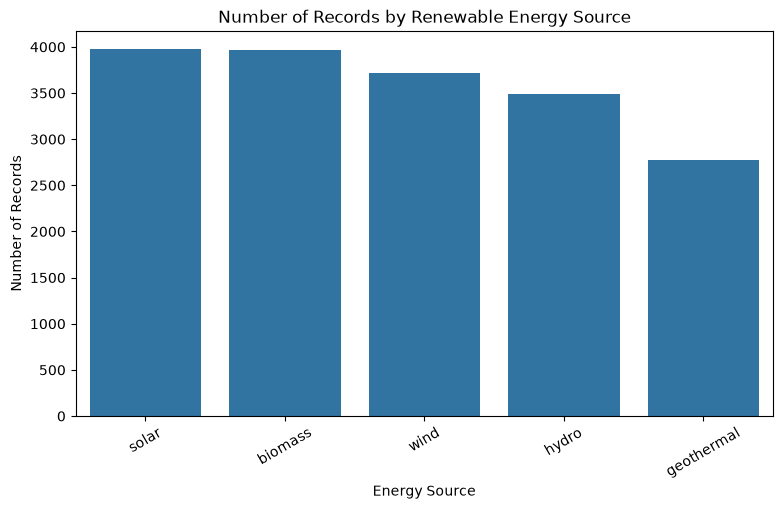

In [17]:
plt.figure(figsize=(9, 5))

sb.countplot(
    data=df,
    x="energy_source",
    order=df["energy_source"].value_counts().index
)

plt.title("Number of Records by Renewable Energy Source")
plt.xlabel("Energy Source")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()

In [18]:
display(
    df.nlargest(15, "generation_gwh")[
        [
            "country_name",
            "year",
            "month",
            "energy_source",
            "generation_gwh",
            "national_consumption_gwh",
            "data_status"
        ]
    ]
)

,country_name,year,month,energy_source,generation_gwh,national_consumption_gwh,data_status
3830,Germany,2024,5,solar,12497100.0,39893.8,provisional
11722,Germany,2025,10,solar,7709510.0,42216.3,estimated
11855,Sweden,2024,3,hydro,5057550.0,12643.7,final
14232,Spain,2020,5,hydro,3191410.0,20058.5,final
2806,Sweden,2025,4,wind,3119800.0,11988.5,provisional
12296,France,2023,5,wind,2705090.0,34682.4,estimated
4116,Spain,2022,6,hydro,2614100.0,21990.8,provisional
1608,Netherlands,2021,11,wind,1961800.0,9162.7,estimated
1976,Sweden,2020,9,wind,1903610.0,12388.8,final
304,Netherlands,2021,6,solar,1755660.0,9447.7,provisional


## 4. Validate generation measurements

Negative readings and readings above the capacity-based monthly maximum are excluded from generation aggregates. Missing capacity prevents this validation for affected rows.


In [19]:
df["hours_in_month"] = (
    df["period_date"].dt.days_in_month * 24
)


df["max_possible_generation_gwh"] = (
    df["installed_capacity_mw"] *
    df["hours_in_month"] / 1000
)


df["impossible_generation"] = (
    df["generation_gwh"] >
    df["max_possible_generation_gwh"]
)

print(
    "Physically impossible generation records:",
    df["impossible_generation"].sum()
)

display(
    df.loc[
        df["impossible_generation"],
        [
            "country_name",
            "year",
            "month",
            "energy_source",
            "generation_gwh",
            "installed_capacity_mw",
            "max_possible_generation_gwh"
        ]
    ].head(10)
)

Physically impossible generation records: 77


,country_name,year,month,energy_source,generation_gwh,installed_capacity_mw,max_possible_generation_gwh
37,Portugal,2018,12,hydro,733290.0,2838.4,2111.7696
304,Netherlands,2021,6,solar,1755660.0,7944.5,5720.0400
502,Serbia,2019,8,solar,163270.0,753.4,560.5296
1023,France,2018,12,geothermal,159280.0,628.9,467.9016
1608,Netherlands,2021,11,wind,1961800.0,8493.0,6114.9600
1859,Switzerland,2025,10,biomass,175960.0,1713.1,1274.5464
1976,Sweden,2020,9,wind,1903610.0,10796.0,7773.1200
2192,Hungary,2015,7,solar,48020.0,189.5,140.9880
2331,Ukraine,2015,2,hydro,1140560.0,4678.2,3143.7504
2475,Ireland,2016,4,hydro,265300.0,882.8,635.6160


In [20]:
df_analysis = df.copy()


invalid_generation = (
    df_analysis["negative_generation"] |
    df_analysis["impossible_generation"]
)

df_analysis.loc[
    invalid_generation,
    "generation_gwh"
] = np.nan

print("Original dataset:", df.shape)
print("Analysis dataset:", df_analysis.shape)

print(
    "Valid generation measurements:",
    df_analysis["generation_gwh"].notna().sum()
)

Original dataset: (17907, 29)
Analysis dataset: (17907, 29)
Valid generation measurements: 17343


## 5. Recorded generation and technology trends

The 2015–2025 totals reflect changing reporting coverage. The 2018–2025 cohort comparison holds country membership constant but does not guarantee complete source-month coverage.


,year,generation_gwh
0,2015,723454.42
1,2016,775412.69
2,2017,904734.33
3,2018,950020.48
4,2019,1111397.90
5,2020,1152997.64
6,2021,1261659.81
7,2022,1318434.98
8,2023,1491255.15
9,2024,1667557.42


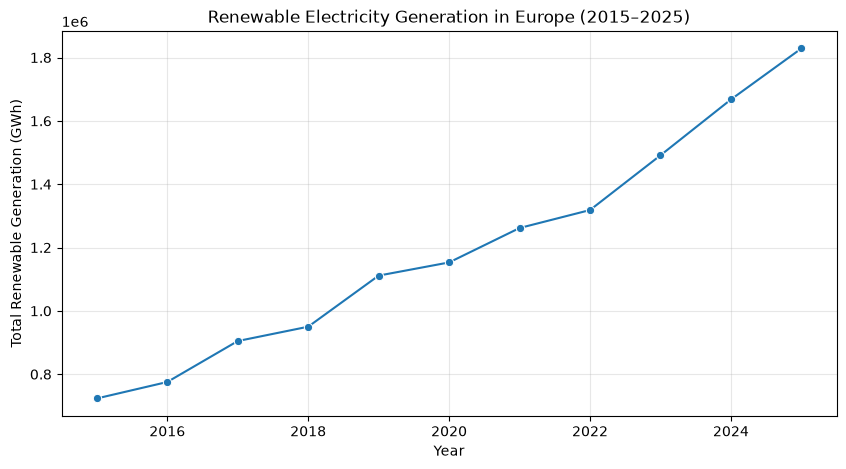

In [21]:
yearly_generation = (
    df_analysis.groupby("year")["generation_gwh"]
    .sum(min_count=1)
    .reset_index()
)

display(yearly_generation)

plt.figure(figsize=(10, 5))

sb.lineplot(
    data=yearly_generation,
    x="year",
    y="generation_gwh",
    marker="o"
)

plt.title("Renewable Electricity Generation in Europe (2015–2025)")
plt.xlabel("Year")
plt.ylabel("Total Renewable Generation (GWh)")
plt.grid(alpha=0.3)
plt.show()

In [22]:
df_recent = df_analysis[
    df_analysis["year"].between(2018, 2025)
].copy()


country_years = (
    df_recent.groupby("country_id")["year"]
    .nunique()
)

common_countries = country_years[
    country_years == 8
].index

print(
    "Countries represented in all 8 years:",
    len(common_countries)
)


df_consistent = df_recent[
    df_recent["country_id"].isin(common_countries)
].copy()

print(
    df_consistent.groupby("year")["country_id"].nunique()
)

Countries represented in all 8 years: 34
year
2018    34
2019    34
2020    34
2021    34
2022    34
2023    34
2024    34
2025    34
Name: country_id, dtype: int64


In [23]:
coverage_check = (
    df_consistent.groupby("year")
    .agg(
        total_records=("record_id", "count"),
        valid_generation=("generation_gwh", "count"),
        countries=("country_id", "nunique")
    )
    .reset_index()
)

coverage_check["valid_pct"] = (
    coverage_check["valid_generation"]
    / coverage_check["total_records"] * 100
)

display(coverage_check)

,year,total_records,valid_generation,countries,valid_pct
0,2018,1691,1633,34,96.570077
1,2019,1693,1645,34,97.164796
2,2020,1667,1617,34,97.000600
3,2021,1678,1628,34,97.020262
4,2022,1692,1644,34,97.163121
5,2023,1680,1633,34,97.202381
6,2024,1676,1623,34,96.837709
7,2025,1665,1612,34,96.816817


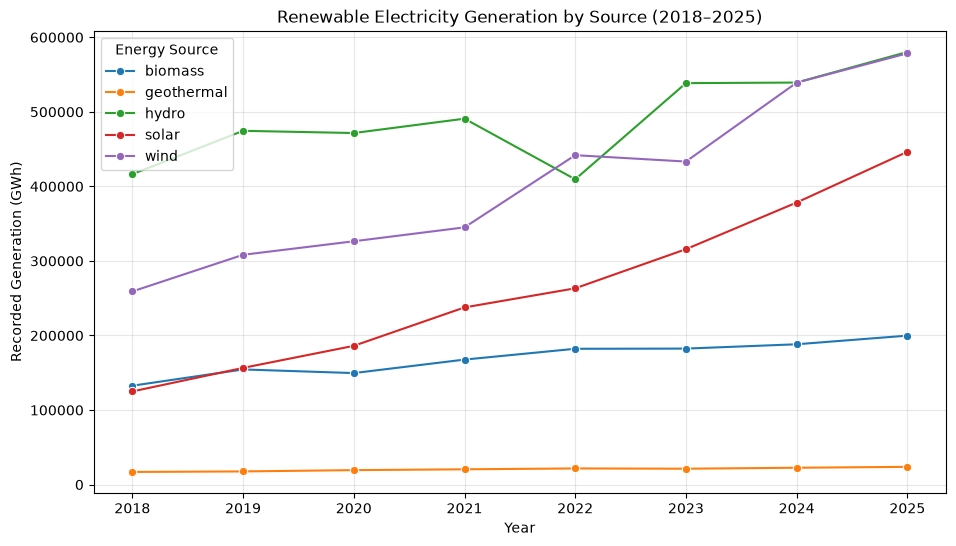

In [24]:
source_trends = (
    df_consistent.groupby(
        ["year", "energy_source"]
    )["generation_gwh"]
    .sum(min_count=1)
    .reset_index()
)

plt.figure(figsize=(11, 6))

sb.lineplot(
    data=source_trends,
    x="year",
    y="generation_gwh",
    hue="energy_source",
    marker="o"
)

plt.title(
    "Renewable Electricity Generation by Source (2018–2025)"
)
plt.xlabel("Year")
plt.ylabel("Recorded Generation (GWh)")
plt.legend(title="Energy Source")
plt.grid(alpha=0.3)
plt.show()

## 6. Country comparisons in 2025

Absolute and per-person generation answer different questions. Population is supplied metadata; verify its reference year before interpreting per-capita comparisons.


In [25]:
df_2025 = df_consistent[
    df_consistent["year"] == 2025
].copy()


country_generation = (
    df_2025.groupby("country_name")
    .agg(
        total_generation_gwh=("generation_gwh", "sum"),
        valid_records=("generation_gwh", "count"),
        total_records=("record_id", "count")
    )
    .reset_index()
)

country_generation["valid_pct"] = (
    country_generation["valid_records"]
    / country_generation["total_records"] * 100
)


country_generation = country_generation.sort_values(
    "total_generation_gwh",
    ascending=False
)

display(country_generation.head(10))

,country_name,total_generation_gwh,valid_records,total_records,valid_pct
10,Germany,327513.79,42,43,97.674419
33,United Kingdom,175713.60,54,56,96.428571
29,Spain,168774.50,43,44,97.727273
14,Italy,148922.05,51,51,100.000000
9,France,129577.53,49,50,98.000000
22,Norway,113777.33,40,41,97.560976
30,Sweden,103214.20,45,47,95.744681
23,Poland,62416.09,51,53,96.226415
20,Netherlands,62240.76,32,32,100.000000
0,Austria,61496.50,43,44,97.727273


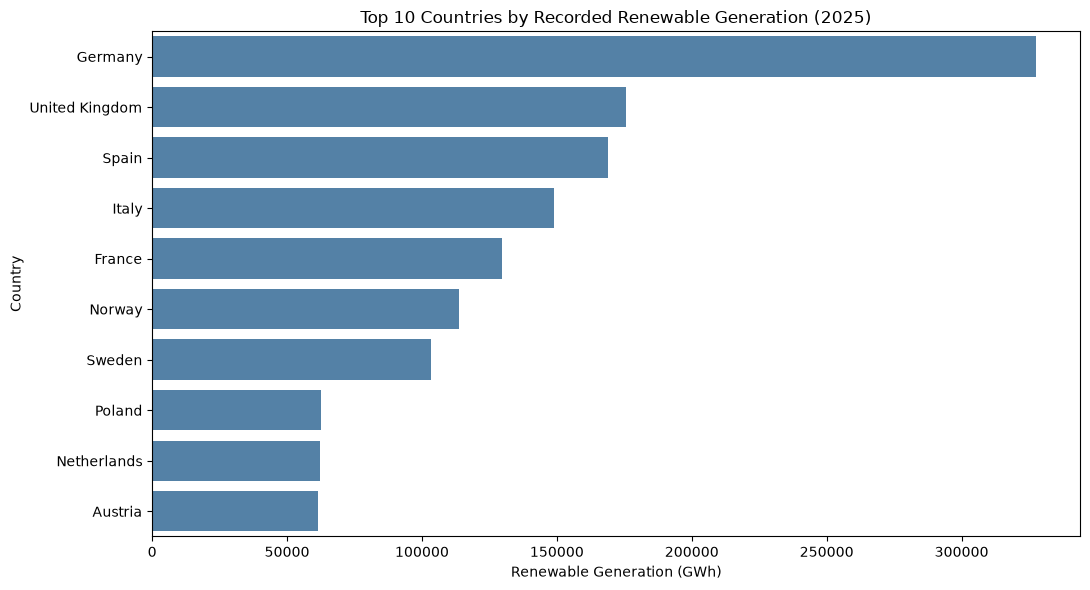

In [26]:
top_10 = country_generation.head(10)

plt.figure(figsize=(11, 6))

sb.barplot(
    data=top_10,
    x="total_generation_gwh",
    y="country_name",
    color="steelblue"
)

plt.title("Top 10 Countries by Recorded Renewable Generation (2025)")
plt.xlabel("Renewable Generation (GWh)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [27]:
country_coverage = (
    df_2025.groupby(["country_name", "energy_source"])
    .agg(
        months_recorded=("month", "nunique"),
        valid_readings=("generation_gwh", "count")
    )
    .reset_index()
)

display(
    country_coverage.sort_values(
        ["country_name", "energy_source"]
    ).head(20)
)

,country_name,energy_source,months_recorded,valid_readings
0,Austria,biomass,11,11
1,Austria,hydro,11,11
2,Austria,solar,10,10
3,Austria,wind,12,11
4,Belgium,biomass,12,12
5,Belgium,geothermal,10,10
6,Belgium,hydro,9,9
7,Belgium,solar,11,11
8,Belgium,wind,11,10
9,Bosnia and Herzegovina,biomass,12,12


### Generation per person

Convert GWh to MWh and population in millions to people: `GWh / (population_millions × 1,000)` gives MWh/person. The correction is applied before sorting and plotting.


In [28]:
country_per_capita = (
    df_2025.groupby(
        ["country_name", "population_millions"],
        as_index=False
    )["generation_gwh"]
    .sum(min_count=1)
)


country_per_capita["mwh_per_person"] = (
    country_per_capita["generation_gwh"]
    / (country_per_capita["population_millions"] * 1000)
)

country_per_capita = country_per_capita.sort_values(
    "mwh_per_person",
    ascending=False
)

display(country_per_capita.head(10))

,country_name,population_millions,generation_gwh,mwh_per_person
22,Norway,5.40,113777.33,21.069876
30,Sweden,10.50,103214.20,9.829924
8,Finland,5.50,48723.13,8.858751
0,Austria,9.00,61496.50,6.832944
6,Denmark,5.90,34589.50,5.862627
19,Montenegro,0.62,2761.01,4.453242
28,Slovenia,2.10,8606.34,4.098257
24,Portugal,10.30,42059.49,4.083446
10,Germany,83.20,327513.79,3.936464
31,Switzerland,8.70,32688.43,3.757291


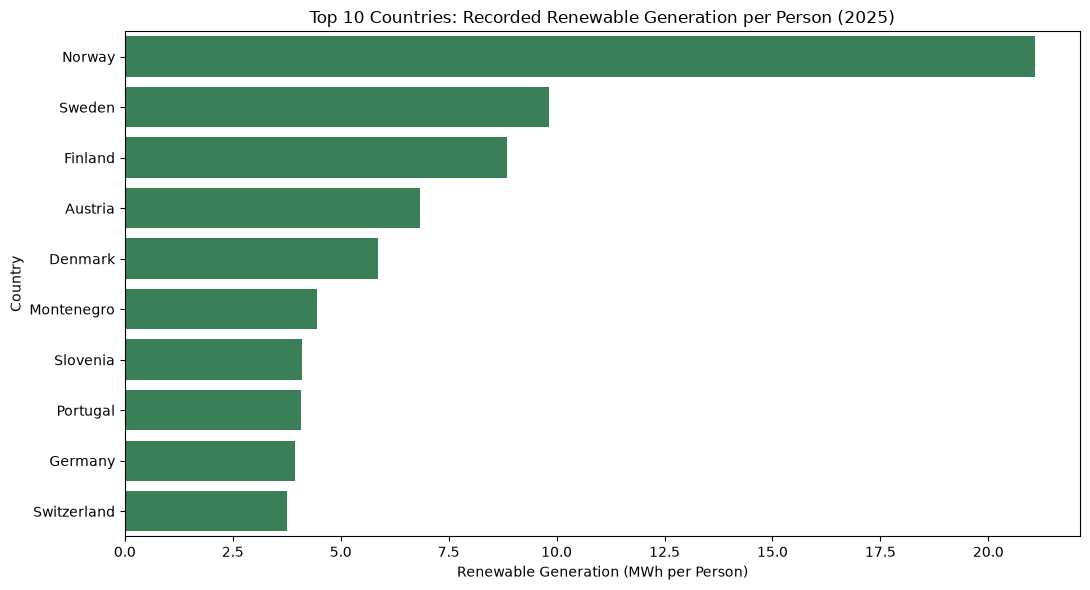

In [29]:
top_10_per_capita = country_per_capita.head(10)

plt.figure(figsize=(11, 6))

sb.barplot(
    data=top_10_per_capita,
    x="mwh_per_person",
    y="country_name",
    color="seagreen"
)

plt.title("Top 10 Countries: Recorded Renewable Generation per Person (2025)")
plt.xlabel("Renewable Generation (MWh per Person)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 7. Supplied 2030 target metadata

These values and their definitions have not been verified against official policy sources. This chart describes supplied metadata, not confirmed national commitments or progress toward targets.


,country_name,target_renewable_share_2030_pct
11,Poland,80.0
8,Finland,80.0
12,Belgium,80.0
14,Greece,80.0
13,Slovenia,65.0
6,Italy,65.0
26,Ireland,65.0
221,Malta,65.0
21,Portugal,60.0
48,Hungary,60.0


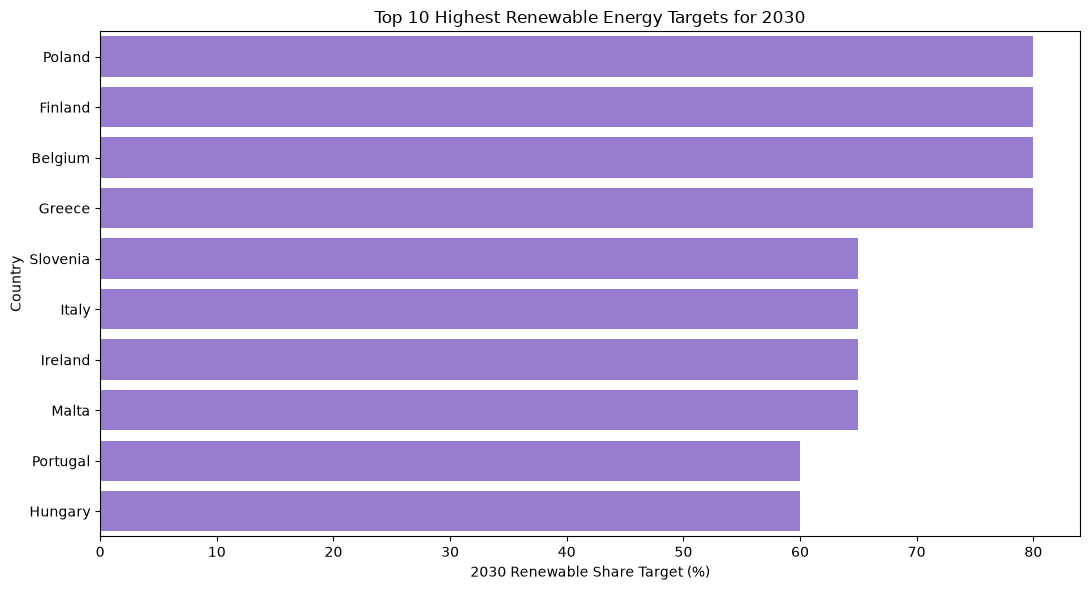

In [30]:
targets = (
    df[[
        "country_name",
        "target_renewable_share_2030_pct"
    ]]
    .drop_duplicates(subset="country_name")
    .dropna()
    .sort_values(
        "target_renewable_share_2030_pct",
        ascending=False
    )
)

display(targets.head(10))

plt.figure(figsize=(11, 6))

sb.barplot(
    data=targets.head(10),
    x="target_renewable_share_2030_pct",
    y="country_name",
    color="mediumpurple"
)

plt.title("Top 10 Highest Renewable Energy Targets for 2030")
plt.xlabel("2030 Renewable Share Target (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 8. Reproduction checks

These checks verify input keys, join coverage, date consistency and the corrected per-person metric. They do not establish external data provenance or completeness.

In [31]:
# Validate the supplied inputs and the corrected derived metric.
assert df_2["country_id"].is_unique, "Country metadata keys must be unique"
assert df_1["country_id"].isin(df_2["country_id"]).all(), "Unmatched country IDs"
assert df_1["period_date"].notna().all(), "Unparseable period dates"
assert (df_1["year"] == df_1["period_date"].dt.year).all(), "Year/date mismatch"
assert (df_1["month"] == df_1["period_date"].dt.month).all(), "Month/date mismatch"
assert not df_1.duplicated(["country_id", "period_date", "energy_source"]).any(), "Duplicate normalized observation keys"
assert (country_per_capita["population_millions"] > 0).all(), "Nonpositive population"
assert np.isclose(100 / (2 * 1000), 0.05), "Unit conversion failed"
assert np.allclose(
    country_per_capita["mwh_per_person"],
    country_per_capita["generation_gwh"] / (country_per_capita["population_millions"] * 1000),
    equal_nan=True,
)
print("Input joins, observation keys, dates and per-person conversion checks passed.")
display(country_per_capita.head(3))


Input joins, observation keys, dates and per-person conversion checks passed.


,country_name,population_millions,generation_gwh,mwh_per_person
22,Norway,5.4,113777.33,21.069876
30,Sweden,10.5,103214.20,9.829924
8,Finland,5.5,48723.13,8.858751
